# AI-Powered Influencer Recommendation System & Buyer Intent Estimator

**Learning notebook** — work through the sections in order. The purpose is to understand each stage, not just produce a ranked list.

The prototype supports two campaign goals: **Direct Sales** and **Mass Brand Awareness**. It compares product text with creator niches, estimates audience intent, applies a bot-risk signal, and estimates price.

## 0. Project setup and data note

The source CSV is expected in the same folder as this notebook. The current dataset contains 1,000 creators and 11 columns. It does not include creator bios, raw comments, measured post reach/views, or conversion outcomes. Later cells use clearly labeled proxies for those missing fields.

Before publishing this project, check the dataset's license and whether redistribution is allowed.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path("influencer_buyer_intent_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Rows and columns:", df.shape)
print(df.columns.tolist())
display(df.head())

Rows and columns: (1000, 11)
['Influencer_ID', 'Platform', 'Niche', 'Tier', 'Followers', 'Engagement_Rate', 'Save_Share_Rate', 'Comment_Intent_Score', 'Bot_Risk_Index', 'CVI', 'Audience_Persona']


,Influencer_ID,Platform,Niche,Tier,Followers,Engagement_Rate,Save_Share_Rate,Comment_Intent_Score,Bot_Risk_Index,CVI,Audience_Persona
0,INF_0001,Instagram,Finance,Micro,41379,7.12,0.25,-0.36,0.30,-0.28,Passive Watchers
1,INF_0002,TikTok,Travel,Micro,74729,2.97,3.22,0.10,0.13,1.99,Casual Browsers
2,INF_0003,YouTube,Fitness,Micro,38378,1.34,2.01,-0.18,0.23,0.86,Passive Watchers
3,INF_0004,YouTube,Gaming,Macro,436128,1.24,0.70,0.22,0.25,0.93,Passive Watchers
4,INF_0005,Instagram,Tech,Micro,59996,1.73,1.10,-0.15,0.21,0.58,Passive Watchers


## 1. Data quality and schema

Check missing values, duplicate creator IDs, data types, and metric ranges. This is the first defense against silently scoring bad or misread data.

In [3]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing"))
print("Duplicate creator IDs:", df["Influencer_ID"].duplicated().sum())
print("Data types:")
print(df.dtypes)

numeric_cols = [
    "Followers", "Engagement_Rate", "Save_Share_Rate",
    "Comment_Intent_Score", "Bot_Risk_Index", "CVI",
]
display(df[numeric_cols].describe().T.round(2))

Missing values per column:


,missing
Influencer_ID,0
Platform,0
Niche,0
Tier,0
Followers,0
Engagement_Rate,0
Save_Share_Rate,0
Comment_Intent_Score,0
Bot_Risk_Index,0
CVI,0


Duplicate creator IDs: 0
Data types:
Influencer_ID               str
Platform                    str
Niche                       str
Tier                        str
Followers                 int64
Engagement_Rate         float64
Save_Share_Rate         float64
Comment_Intent_Score    float64
Bot_Risk_Index          float64
CVI                     float64
Audience_Persona            str
dtype: object


,count,mean,std,min,25%,50%,75%,max
Followers,1000.0,381351.02,1300599.78,1018.00,6543.50,32869.50,88328.50,9975681.00
Engagement_Rate,1000.0,4.61,2.22,0.81,2.70,4.58,6.58,8.50
Save_Share_Rate,1000.0,2.05,1.09,0.20,1.10,2.04,2.94,4.00
Comment_Intent_Score,1000.0,0.17,0.40,-0.50,-0.17,0.15,0.50,0.89
Bot_Risk_Index,1000.0,0.18,0.10,0.01,0.10,0.18,0.26,0.35
CVI,1000.0,1.54,0.80,-0.38,0.96,1.52,2.09,3.60


## 2. Explore audience personas

Compare average behavior signals by the supplied persona label. Means are descriptive summaries; they do not prove that a feature causes purchases.

In [4]:
persona_summary = (
    df.groupby("Audience_Persona")
      .agg(
          creator_count=("Influencer_ID", "count"),
          avg_followers=("Followers", "mean"),
          avg_engagement_rate=("Engagement_Rate", "mean"),
          avg_save_share_rate=("Save_Share_Rate", "mean"),
          avg_comment_intent=("Comment_Intent_Score", "mean"),
          avg_bot_risk=("Bot_Risk_Index", "mean"),
          avg_cvi=("CVI", "mean"),
      )
      .round(2)
)
display(persona_summary)
print((df["Audience_Persona"].value_counts(normalize=True) * 100).round(1))

,creator_count,avg_followers,avg_engagement_rate,avg_save_share_rate,avg_comment_intent,avg_bot_risk,avg_cvi
Audience_Persona,,,,,,,
Casual Browsers,471,403258.68,4.71,2.39,0.42,0.16,2.10
High-Intent Buyers,37,170434.05,4.47,3.49,0.75,0.11,3.18
Passive Watchers,492,376240.10,4.52,1.62,-0.11,0.20,0.88


Audience_Persona
Passive Watchers      49.2
Casual Browsers       47.1
High-Intent Buyers     3.7
Name: proportion, dtype: float64


## 3. Check for label leakage

The supplied persona labels align with CVI bands. This suggests the labels may have been generated from CVI. If a model is asked to predict persona, CVI must be excluded; even the other CVI components may let the model reproduce the labeling rules. Treat the result as label imitation unless independent purchase labels are available.

In [5]:
cvi_band = pd.cut(
    df["CVI"],
    bins=[-float("inf"), 1.5, 3.0, float("inf")],
    labels=["Low CVI", "Mid CVI", "High CVI"],
)
display(pd.crosstab(cvi_band, df["Audience_Persona"], normalize="index").round(2))

Audience_Persona,Casual Browsers,High-Intent Buyers,Passive Watchers
CVI,,,
Low CVI,0.0,0.0,1.0
Mid CVI,1.0,0.0,0.0
High CVI,0.0,1.0,0.0


## 4. Train a baseline persona classifier

`X` contains model inputs and `y` contains the persona label. We drop the ID because it is only a key, and CVI because it appears to define the label. One-hot encoding handles categories; scaling puts numeric columns on comparable ranges. The pipeline keeps preprocessing together with the classifier.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["Influencer_ID", "Audience_Persona", "CVI"])
y = df["Audience_Persona"]

categorical_features = ["Platform", "Niche", "Tier"]
numeric_features = [
    "Followers", "Engagement_Rate", "Save_Share_Rate",
    "Comment_Intent_Score", "Bot_Risk_Index",
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numbers", StandardScaler(), numeric_features),
    ]
)
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
model.fit(X_train, y_train)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 800 | Test rows: 200


## 5. Evaluate the baseline

Review per-class precision and recall, especially for High-Intent Buyers. The buyer class is rare, so overall accuracy alone can hide poor buyer precision.

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

pred_test = model.predict(X_test)
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pred_test), 3))
print(classification_report(y_test, pred_test, zero_division=0))
cm = confusion_matrix(y_test, pred_test, labels=model.classes_)
display(pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in model.classes_],
    columns=[f"Predicted: {label}" for label in model.classes_],
))

Balanced accuracy: 0.954
                    precision    recall  f1-score   support

   Casual Browsers       0.99      0.87      0.93        94
High-Intent Buyers       0.44      1.00      0.62         8
  Passive Watchers       0.98      0.99      0.98        98

          accuracy                           0.94       200
         macro avg       0.80      0.95      0.84       200
      weighted avg       0.96      0.94      0.94       200



,Predicted: Casual Browsers,Predicted: High-Intent Buyers,Predicted: Passive Watchers
Actual: Casual Browsers,82,10,2
Actual: High-Intent Buyers,0,8,0
Actual: Passive Watchers,1,0,97


## 6. Out-of-fold buyer scores and decision threshold

Each out-of-fold prediction comes from a model that did not train on that row. Compare a buyer-score cutoff on the out-of-fold predictions. These metrics measure agreement with the supplied persona labels, not real purchases.

In [8]:
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = cross_val_predict(model, X, y, cv=cv, method="predict_proba")
oof_predicted_personas = cross_val_predict(model, X, y, cv=cv, method="predict")
buyer_column = list(model.classes_).index("High-Intent Buyers")
oof_buyer_scores = oof_probabilities[:, buyer_column]

actual_buyer = y.eq("High-Intent Buyers")
selected_as_buyer = oof_buyer_scores >= 0.80
print("Creators selected:", int(selected_as_buyer.sum()))
print("Buyer precision:", round(precision_score(actual_buyer, selected_as_buyer, zero_division=0), 3))
print("Buyer recall:", round(recall_score(actual_buyer, selected_as_buyer, zero_division=0), 3))

Creators selected: 35
Buyer precision: 0.886
Buyer recall: 0.838


## 7. Product-to-niche matching with TF-IDF

The CSV has niche labels but no bios. A hand-written niche vocabulary makes this a category-level TF-IDF demonstration. Replace it with real creator bios and validated product text for richer semantic matching.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

niche_descriptions = {
    "Tech": "technology electronics gadgets audio headphones earbuds wireless devices",
    "Beauty & Skincare": "beauty skincare cosmetics makeup haircare",
    "Finance": "finance investing banking money personal finance",
    "Gaming": "video games esports gaming streams consoles",
    "Travel": "travel destinations tourism hotels trip planning",
    "Fitness": "fitness workouts exercise training wellness",
}
creator_text = df["Niche"].map(niche_descriptions).fillna(df["Niche"].astype(str))
product_query = "Wireless Earbuds, Tech, wireless audio, headphones, consumer electronics"
vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words="english")
text_matrix = vectorizer.fit_transform(creator_text.tolist() + [product_query])
df["Semantic_Match_Score"] = cosine_similarity(text_matrix[-1], text_matrix[:-1]).ravel()
display(
    df[["Niche", "Semantic_Match_Score"]]
      .drop_duplicates("Niche")
      .sort_values("Semantic_Match_Score", ascending=False)
)

,Niche,Semantic_Match_Score
4,Tech,0.227572
0,Finance,0.000000
1,Travel,0.000000
2,Fitness,0.000000
3,Gaming,0.000000
9,Beauty & Skincare,0.000000


## 8. Reach, views, and pricing assumptions

Measured reach and views are absent, so platform factors estimate them from followers. CPM multipliers and the $75 minimum fee are demo assumptions. Replace them with observed creator performance and campaign rates before making commercial claims.

In [10]:
platform_reach_rate = {"Instagram": 0.20, "YouTube": 0.25, "TikTok": 0.30}
platform_views_per_reach = {"Instagram": 1.35, "YouTube": 1.75, "TikTok": 1.60}
niche_cpm = {"Tech": 18, "Finance": 24, "Fitness": 14, "Beauty & Skincare": 15, "Gaming": 12, "Travel": 16}
platform_price_factor = {"Instagram": 1.00, "YouTube": 1.18, "TikTok": 0.88}

awareness_candidates = df[df["Semantic_Match_Score"] > 0].copy()
awareness_candidates["Estimated Reach per Post"] = (
    awareness_candidates["Followers"] * awareness_candidates["Platform"].map(platform_reach_rate)
)
awareness_candidates["Estimated Views per Post"] = (
    awareness_candidates["Estimated Reach per Post"]
    * awareness_candidates["Platform"].map(platform_views_per_reach)
)
reference_engagement = df["Engagement_Rate"].median()
awareness_candidates["Engagement_Factor"] = (
    0.8 + 0.2 * awareness_candidates["Engagement_Rate"] / reference_engagement
).clip(0.75, 1.35)
awareness_candidates["Estimated Sponsorship Cost ($)"] = (
    awareness_candidates["Estimated Reach per Post"] / 1000
    * awareness_candidates["Niche"].map(niche_cpm).fillna(12)
    * awareness_candidates["Platform"].map(platform_price_factor).fillna(1.0)
    * awareness_candidates["Engagement_Factor"]
    + awareness_candidates["Followers"] / 1000 * 0.35
).clip(lower=75).round(2)

awareness_candidates["Reach Rank"] = awareness_candidates["Estimated Reach per Post"].rank(pct=True)
awareness_candidates["Views Rank"] = awareness_candidates["Estimated Views per Post"].rank(pct=True)
awareness_candidates["Awareness Score"] = (
    0.45 * awareness_candidates["Views Rank"]
    + 0.35 * awareness_candidates["Reach Rank"]
    + 0.20 * (1 - awareness_candidates["Bot_Risk_Index"])
)

## 9. Rank and export recommendations

Direct-sales ranking emphasizes the out-of-fold buyer score, niche similarity, and low bot risk. Awareness ranking emphasizes estimated views, estimated reach, and low bot risk. The saved tables are demonstrations using the assumptions above.

In [11]:
all_tech_candidates = df[df["Semantic_Match_Score"] > 0].copy()
all_tech_candidates["Buyer class score (%)"] = oof_buyer_scores[all_tech_candidates.index] * 100
buyer_scores = oof_buyer_scores[all_tech_candidates.index]
all_tech_candidates["Direct sales score (%)"] = 100 * (
    0.55 * buyer_scores
    + 0.25 * all_tech_candidates["Semantic_Match_Score"]
    + 0.20 * (1 - all_tech_candidates["Bot_Risk_Index"])
)

pricing_lookup = awareness_candidates[[
    "Influencer_ID", "Estimated Reach per Post", "Estimated Views per Post",
    "Estimated Sponsorship Cost ($)",
]].drop_duplicates("Influencer_ID")
direct_sales_candidates = all_tech_candidates.merge(
    pricing_lookup, on="Influencer_ID", how="left", validate="one_to_one"
)
direct_sales_candidates["Estimated Engagements"] = (
    direct_sales_candidates["Followers"] * direct_sales_candidates["Engagement_Rate"] / 100
).clip(lower=1)
direct_sales_candidates["CPE ($)"] = (
    direct_sales_candidates["Estimated Sponsorship Cost ($)"]
    / direct_sales_candidates["Estimated Engagements"]
).round(2)
direct_sales_candidates["CPM ($)"] = (
    direct_sales_candidates["Estimated Sponsorship Cost ($)"]
    / direct_sales_candidates["Estimated Reach per Post"] * 1000
).round(2)

budget_usd = 3000
direct_sales_affordable = direct_sales_candidates[
    (direct_sales_candidates["Buyer class score (%)"] >= 80)
    & (direct_sales_candidates["Estimated Sponsorship Cost ($)"] <= budget_usd)
].copy()
affordable_awareness = awareness_candidates[
    awareness_candidates["Estimated Sponsorship Cost ($)"] <= budget_usd
].copy()

direct_sales_affordable.to_csv(OUTPUT_DIR / "direct_sales_recommendation.csv", index=False)
affordable_awareness.sort_values("Awareness Score", ascending=False).head(10).to_csv(
    OUTPUT_DIR / "awareness_recommendations.csv", index=False
)
print("Recommendation CSVs saved under", OUTPUT_DIR.resolve())

Recommendation CSVs saved under C:\Users\DELL i5\Desktop\INFLUENCER\outputs


## 10. Buyer vs. Watcher visualization

Compare the average save/share rate, comment intent, bot risk, and CVI by persona. The feature units differ, so interpret each metric using its own scale.

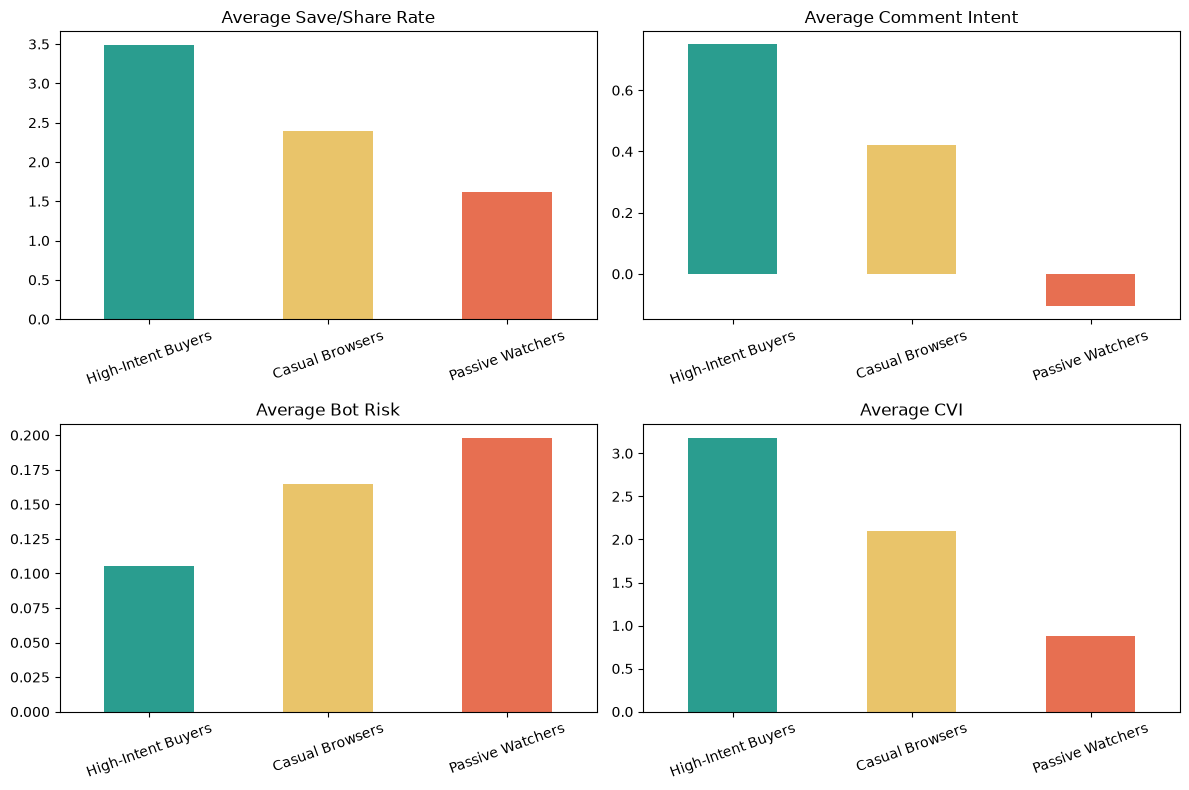

In [12]:
import matplotlib.pyplot as plt

persona_order = ["High-Intent Buyers", "Casual Browsers", "Passive Watchers"]
metrics = ["Save_Share_Rate", "Comment_Intent_Score", "Bot_Risk_Index", "CVI"]
persona_means = df.groupby("Audience_Persona")[metrics].mean().reindex(persona_order)
titles = ["Average Save/Share Rate", "Average Comment Intent", "Average Bot Risk", "Average CVI"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric, title in zip(axes.flat, metrics, titles):
    persona_means[metric].plot(
        kind="bar", ax=ax, color=["#2a9d8f", "#e9c46a", "#e76f51"]
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "buyer_vs_watcher_metrics.png", dpi=200, bbox_inches="tight")
plt.show()